In [2]:
# Step 1. Problem Understanding & Framing 
# Problems of companies include unknown, large, and complex customer behavior and product preferences vis a vis limited company budget or resources.
# This kind of problem about customer personality was solved using Clustering Algorithm in Machine Learning.
# Success metrics was evaluated and interpreted based on Silhouette Score. 
# Success metrics for business KPIs included cost savings and decrease in marketing cost or increase in sales revenue.
# ML Workflow included Data Preparation, Preprocessing, Dimensionality Reduction, Cluster Validation, and Model execution & business profiling.


# Step 2. Data Collection & Understanding 
# The public data of Customer Preference Analysis was sourced from Kaggle. Source: https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis
# Overview of dataset was presented that includes feature types, missing values, outliers, and distributions.
# Data dictionary such as variables, types, ranges/units was presented
# Necessary libraries imported.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('marketing_campaign_aim.csv')
# Display first 5 rows
print(df.head())

# Dataset shape and info
print(f"Dataset Shape: {df.shape}")
print(df.info())

# Summary statistics
print(df.describe())

# Check for missing values
print(df.isnull().sum())

# Check for duplicates
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")

     ID  Year_Birth   Education Marital_Status   Income  Kidhome  Teenhome  \
0  5524        1957  Graduation         Single  58138.0        0         0   
1  2174        1954  Graduation         Single  46344.0        1         1   
2  4141        1965  Graduation       Together  71613.0        0         0   
3  6182        1984  Graduation       Together  26646.0        1         0   
4  5324        1981         PhD        Married  58293.0        1         0   

   Recency  MntWines  MntFruits  ...  NumWebVisitsMonth  AcceptedCmp3  \
0       58       635         88  ...                  7             0   
1       38        11          1  ...                  5             0   
2       26       426         49  ...                  4             0   
3       26        11          4  ...                  6             0   
4       94       173         43  ...                  5             0   

   AcceptedCmp4  AcceptedCmp5  AcceptedCmp1  AcceptedCmp2  Complain  \
0             0      

In [3]:
# Get the names of all columns that contain text/object data
text_columns = df.select_dtypes(include=["object", "category"]).columns.tolist()

print(f"Your text columns are: {text_columns}")

# Loop through them to see the unique values in every single text column
for col in text_columns:
    print(f"\n--- Unique values in '{col}' ---")
    print(df[col].unique())

Your text columns are: ['Education', 'Marital_Status']

--- Unique values in 'Education' ---
['Graduation' 'PhD' 'Master' 'Basic' 'Cycle']

--- Unique values in 'Marital_Status' ---
['Single' 'Together' 'Married' 'Divorced' 'Widow' 'Alone' 'Absurd' 'YOLO']


In [4]:
# Apply One-Hot Encoding. 'columns' specifies exactly which text columns to convert.
# 'dtype=int' changes the True/False output to clean 1s and 0s.

df = pd.read_csv('marketing_campaign_aim.csv')
df_encoded = pd.get_dummies(df, columns=['Education', 'Marital_Status'], dtype=int)

print("\n--- Encoded Data ---")
print(df_encoded.head())


--- Encoded Data ---
     ID  Year_Birth   Income  Kidhome  Teenhome  Recency  MntWines  MntFruits  \
0  5524        1957  58138.0        0         0       58       635         88   
1  2174        1954  46344.0        1         1       38        11          1   
2  4141        1965  71613.0        0         0       26       426         49   
3  6182        1984  26646.0        1         0       26        11          4   
4  5324        1981  58293.0        1         0       94       173         43   

   MntMeatProducts  MntFishProducts  ...  Education_Master  Education_PhD  \
0              546              172  ...                 0              0   
1                6                2  ...                 0              0   
2              127              111  ...                 0              0   
3               20               10  ...                 0              0   
4              118               46  ...                 0              1   

   Marital_Status_Absurd  Ma

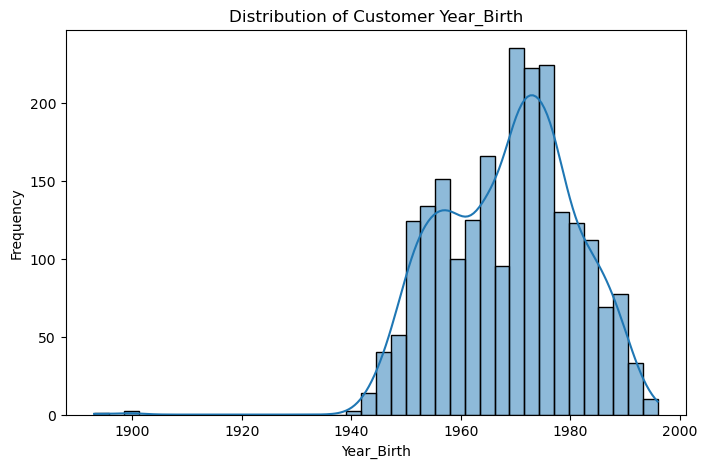

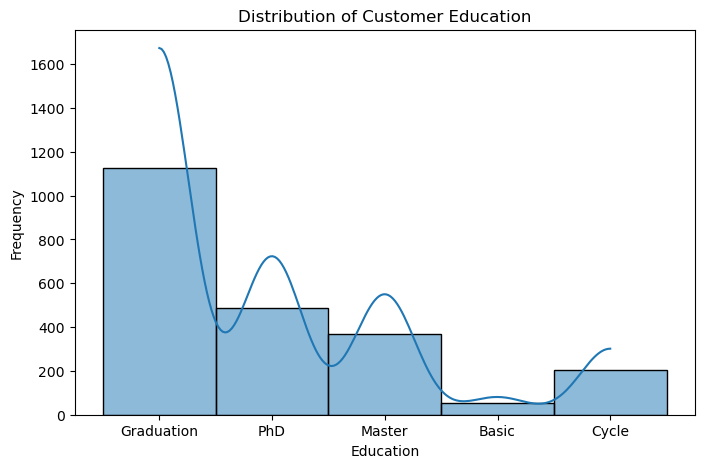

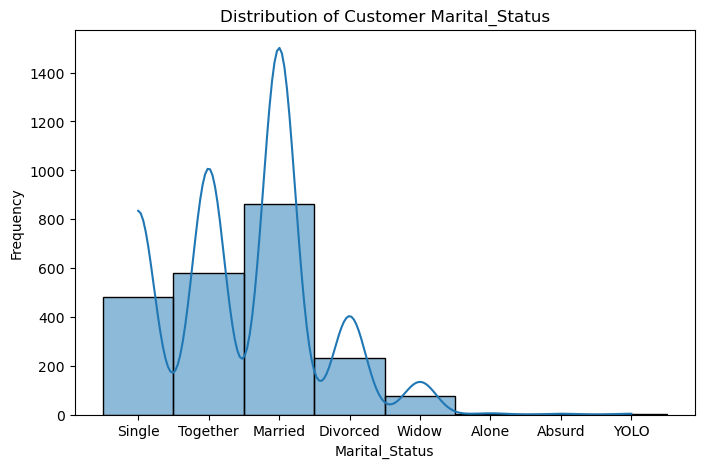

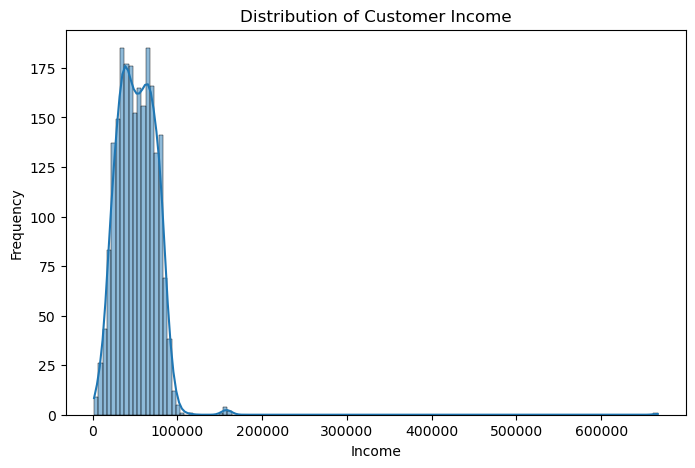

In [5]:
# Plot distributions
plt.figure(figsize=(8, 5))
sns.histplot(df['Year_Birth'], kde=True)
plt.title('Distribution of Customer Year_Birth')
plt.xlabel('Year_Birth')
plt.ylabel('Frequency')
plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(df['Education'], kde=True)
plt.title('Distribution of Customer Education')
plt.xlabel('Education')
plt.ylabel('Frequency')
plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(df['Marital_Status'], kde=True)
plt.title('Distribution of Customer Marital_Status')
plt.xlabel('Marital_Status')
plt.ylabel('Frequency')
plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(df['Income'], kde=True)
plt.title('Distribution of Customer Income')
plt.xlabel('Income')
plt.ylabel('Frequency')
plt.show()

     ID  Year_Birth   Education Marital_Status   Income  Kidhome  Teenhome  \
0  5524        1957  Graduation         Single  58138.0        0         0   
1  2174        1954  Graduation         Single  46344.0        1         1   
2  4141        1965  Graduation       Together  71613.0        0         0   
3  6182        1984  Graduation       Together  26646.0        1         0   
4  5324        1981         PhD        Married  58293.0        1         0   

   Recency  MntWines  MntFruits  ...  NumWebVisitsMonth  AcceptedCmp3  \
0       58       635         88  ...                  7             0   
1       38        11          1  ...                  5             0   
2       26       426         49  ...                  4             0   
3       26        11          4  ...                  6             0   
4       94       173         43  ...                  5             0   

   AcceptedCmp4  AcceptedCmp5  AcceptedCmp1  AcceptedCmp2  Complain  \
0             0      

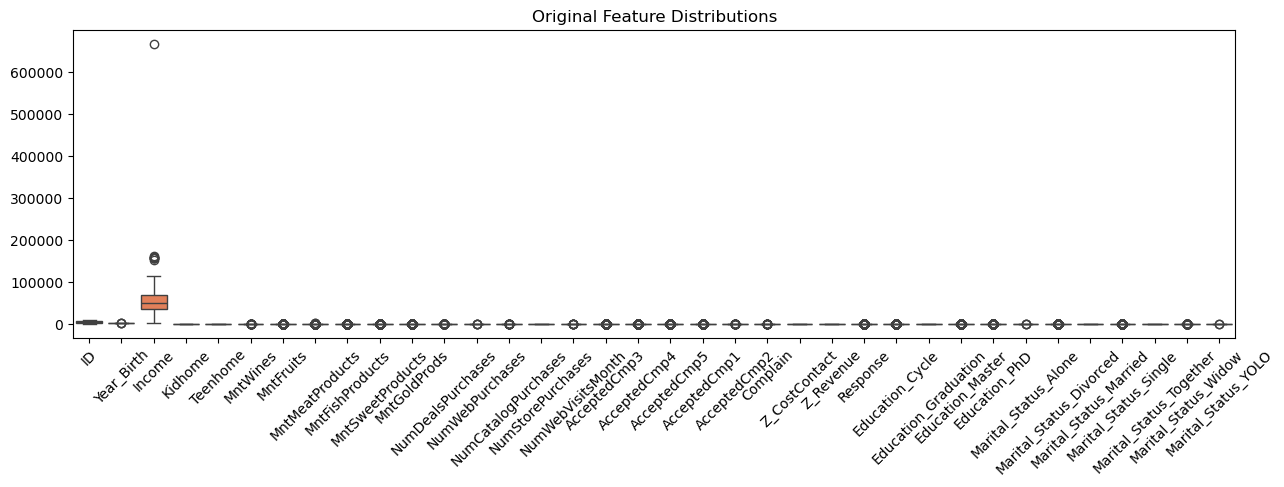

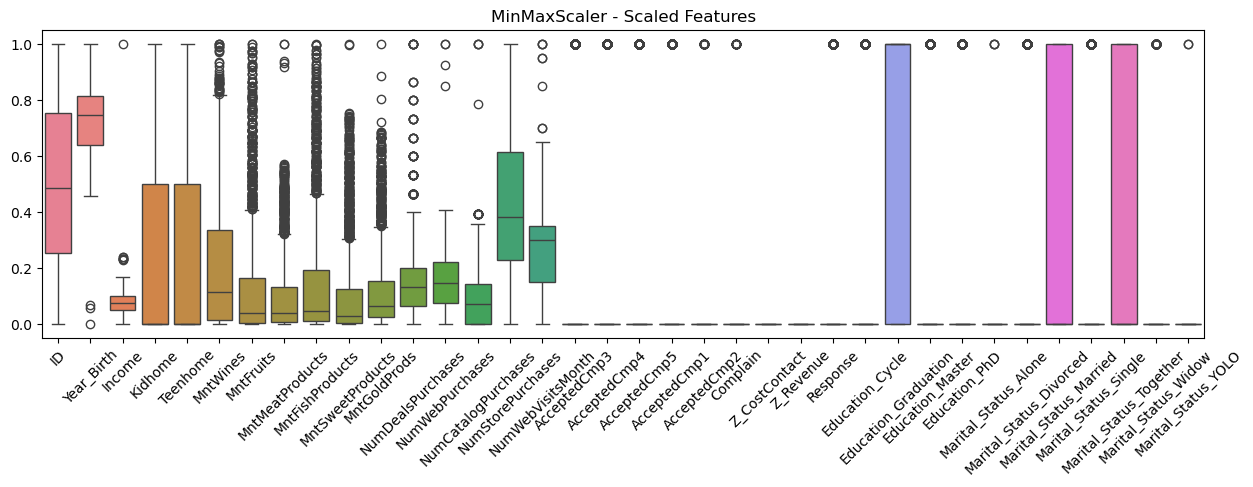

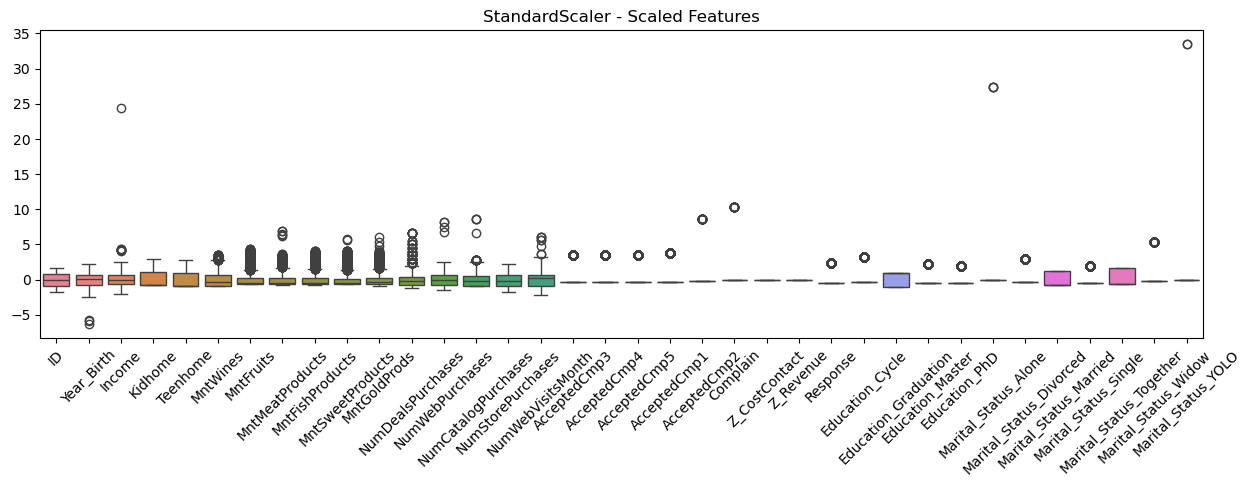

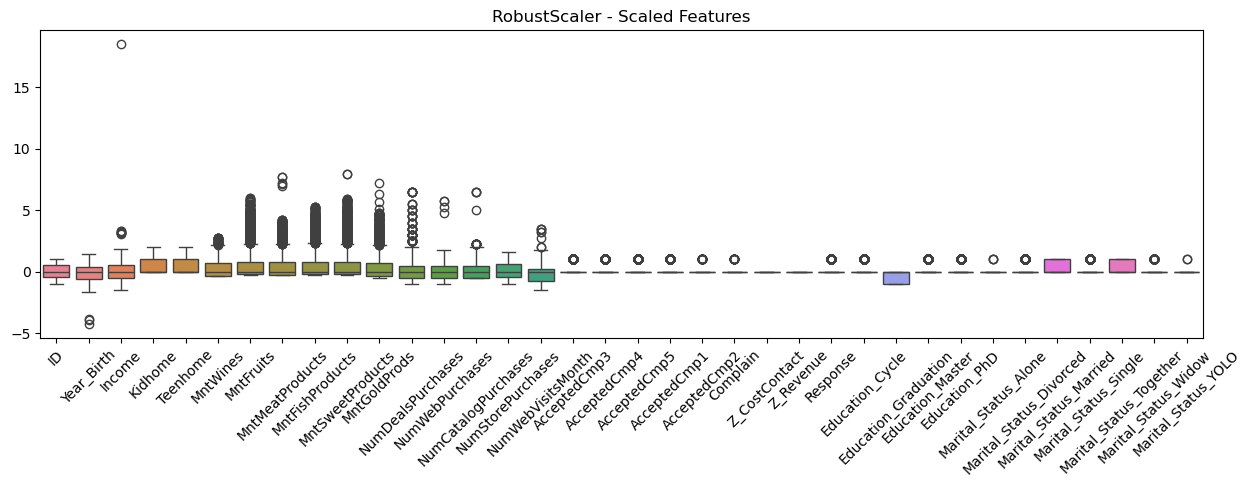

In [13]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

# Load dataset
df = pd.read_csv("marketing_campaign_aim.csv")  
print(df.head())

# Check for missing values
print("\nMissing Values:\n", df.isnull().sum())

# Convert categories into binary numeric columns
df = pd.get_dummies(df, columns=['Education','Marital_Status'], drop_first=True)

# Drop target column for scaling
X = df.drop("Recency", axis=1)
y = df["Recency"]

# Apply scalers
scalers = {
    "MinMaxScaler": MinMaxScaler(),
    "StandardScaler": StandardScaler(),
    "RobustScaler": RobustScaler()
}

scaled_dfs = {}
for name, scaler in scalers.items():
    X_scaled = scaler.fit_transform(X)
    scaled_dfs[name] = pd.DataFrame(X_scaled, columns=X.columns)

# Boxplot before scaling
plt.figure(figsize=(15, 4))
sns.boxplot(data=X)
plt.title("Original Feature Distributions")
plt.xticks(rotation=45)
plt.show()

# Boxplots after scaling
for name, df_scaled in scaled_dfs.items():
    plt.figure(figsize=(15, 4))
    sns.boxplot(data=df_scaled)
    plt.title(f"{name} - Scaled Features")
    plt.xticks(rotation=45)
    plt.show()

In [6]:
# Data Dictionary and limits
# 1. Specify the feature name and target range
filter_ranges = [
    ['Year_Birth',1920,2000],
    ['Income',0,120000],
    ['MntWines',0, 1000],
    ['MntFruits',0, 150],
    ['MntMeatProducts',0,1000],
    ['MntFishProducts',0,300],
    ['MntSweetProducts',0,300],
    ['MntGoldProds',0,400],
    ['NumDealsPurchases',0,30],
    ['NumWebPurchases',0,30],
    ['NumCatalogPurchases',0,30],
    ['NumStorePurchases',0,30],
    ['NumWebVisitsMonth',0,30]
         ]
  
# 2. Filter the entire DataFrame based on that specific feature
filtered_df=df.copy()
for feature,lower_limit,upper_limit in filter_ranges:
    filtered_df = filtered_df[filtered_df[feature].between(lower_limit, upper_limit)]

print(filtered_df)
filtered_df.describe()

         ID  Year_Birth   Education Marital_Status   Income  Kidhome  \
0      5524        1957  Graduation         Single  58138.0        0   
1      2174        1954  Graduation         Single  46344.0        1   
2      4141        1965  Graduation       Together  71613.0        0   
3      6182        1984  Graduation       Together  26646.0        1   
4      5324        1981         PhD        Married  58293.0        1   
...     ...         ...         ...            ...      ...      ...   
2213   8207        1957       Cycle        Married  53233.0        0   
2214   8722        1957       Cycle        Married  82347.0        0   
2215    607        1955       Cycle       Divorced  41769.0        0   
2216   3661        1995       Cycle         Single  80617.0        0   
2217  10659        1979       Cycle       Together   7500.0        1   

      Teenhome  Recency  MntWines  MntFruits  ...  NumWebVisitsMonth  \
0            0       58       635         88  ...              

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,...,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,2038.0,2038.0,2038.000000
mean,5579.081943,1969.019627,49709.610402,0.471541,0.520608,49.216389,254.354760,21.726202,147.153582,34.161923,...,5.434740,0.069185,0.056428,0.046124,0.044161,0.006869,0.009814,3.0,11.0,0.129539
std,3268.377836,11.584638,20083.346665,0.542657,0.545718,29.044374,275.224786,31.839630,204.440485,52.001324,...,2.390541,0.253832,0.230803,0.209804,0.205503,0.082617,0.098600,0.0,0.0,0.335878
min,0.000000,1940.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2755.750000,1960.000000,34176.000000,0.000000,0.000000,24.000000,21.000000,1.000000,14.000000,2.000000,...,4.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,48918.000000,0.000000,0.000000,50.000000,151.000000,7.000000,56.000000,11.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8429.250000,1977.000000,65487.000000,1.000000,1.000000,74.000000,437.750000,28.000000,185.750000,41.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,113734.000000,2.000000,2.000000,99.000000,1000.000000,149.000000,984.000000,259.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000


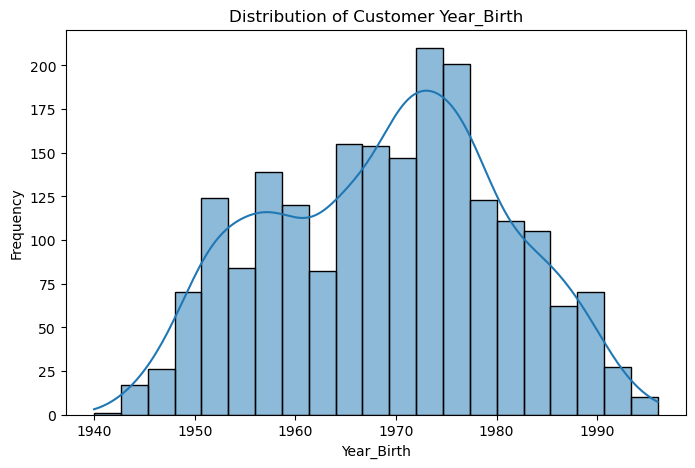

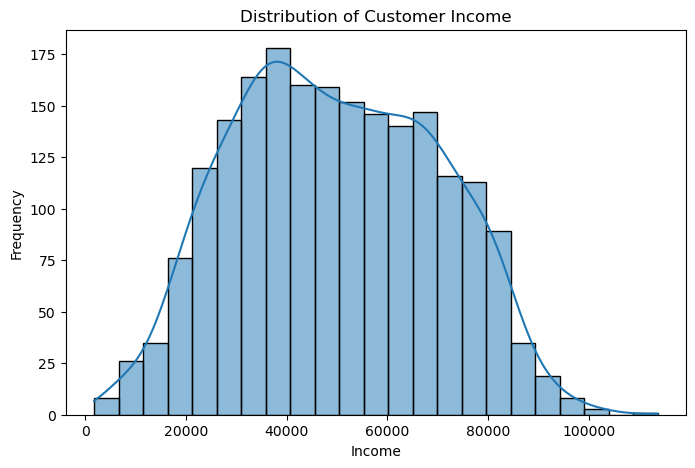

In [7]:
# Plot distributions within specified range
plt.figure(figsize=(8, 5))
sns.histplot(filtered_df['Year_Birth'], kde=True)
plt.title('Distribution of Customer Year_Birth')
plt.xlabel('Year_Birth')
plt.ylabel('Frequency')
plt.show()

# Plot distributions
plt.figure(figsize=(8, 5))
sns.histplot(filtered_df['Income'], kde=True)
plt.title('Distribution of Customer Income')
plt.xlabel('Income')
plt.ylabel('Frequency')
plt.show()

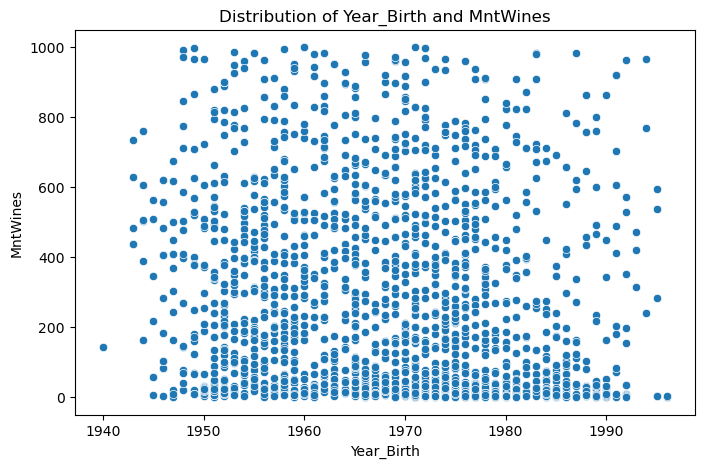

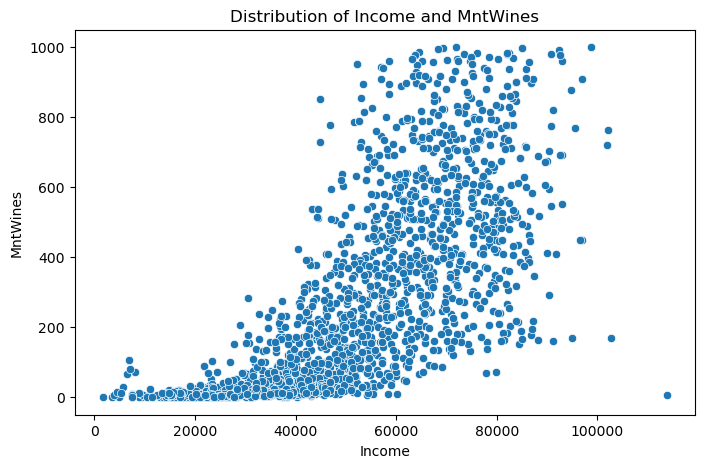

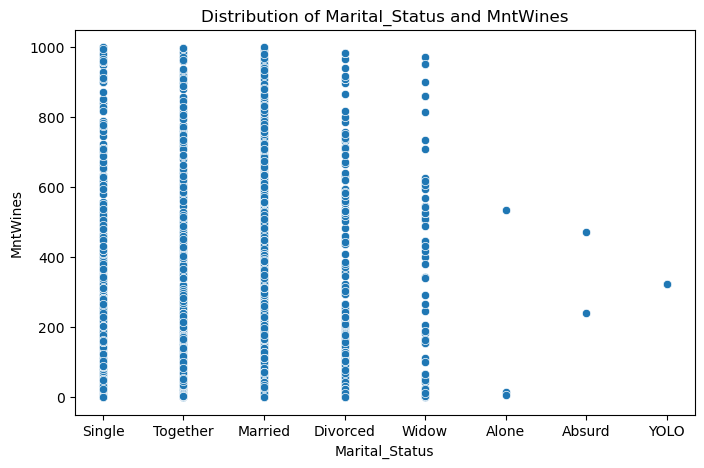

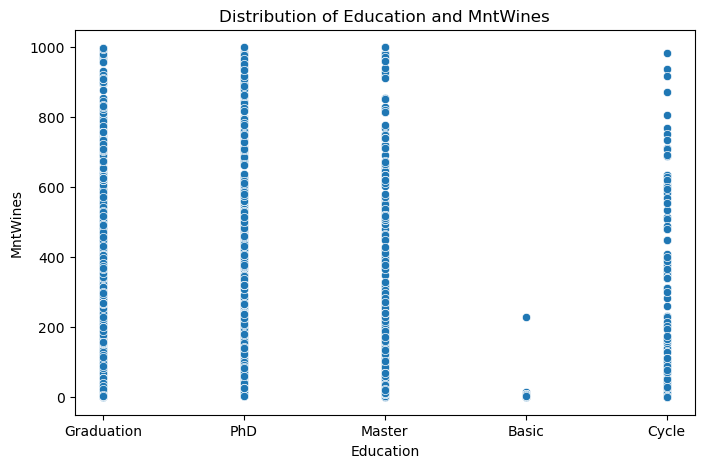

In [8]:
# Plot distributions 
plt.figure(figsize=(8, 5))
sns.scatterplot(data=filtered_df, x="Year_Birth", y="MntWines")
plt.title('Distribution of Year_Birth and MntWines')
plt.xlabel('Year_Birth')
plt.ylabel('MntWines')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=filtered_df, x="Income", y="MntWines")
plt.title('Distribution of Income and MntWines')
plt.xlabel('Income')
plt.ylabel('MntWines')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=filtered_df, x="Marital_Status", y="MntWines")
plt.title('Distribution of Marital_Status and MntWines')
plt.xlabel('Marital_Status')
plt.ylabel('MntWines')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=filtered_df, x="Education", y="MntWines")
plt.title('Distribution of Education and MntWines')
plt.xlabel('Education')
plt.ylabel('MntWines')
plt.show()

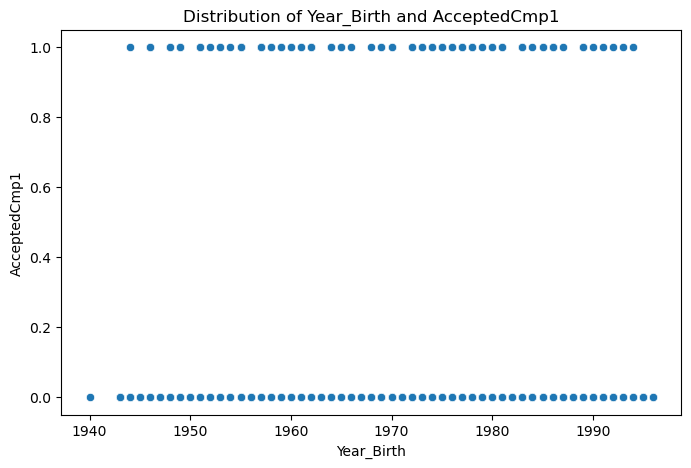

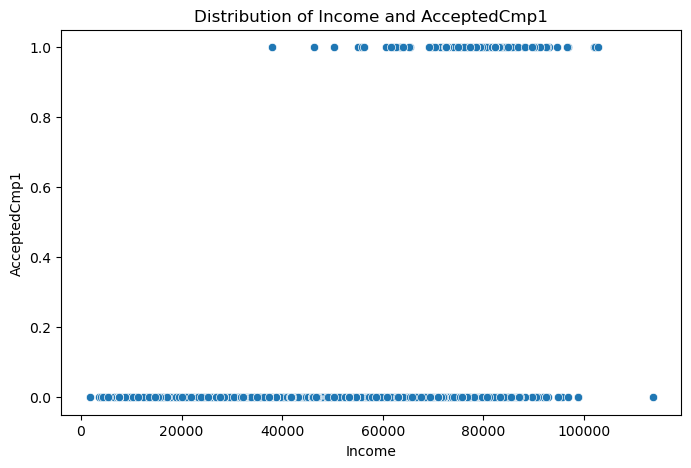

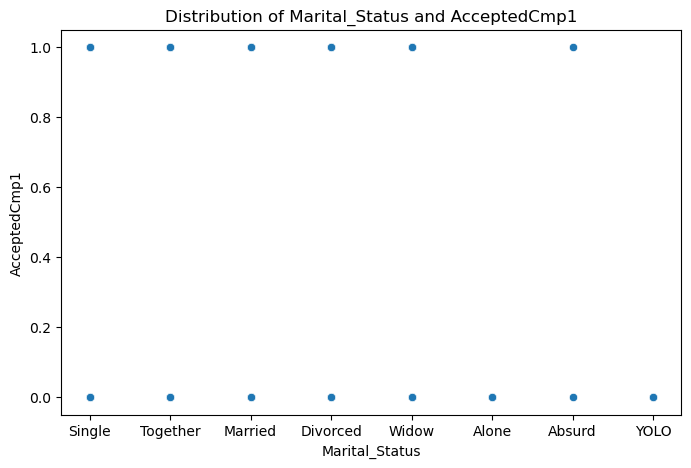

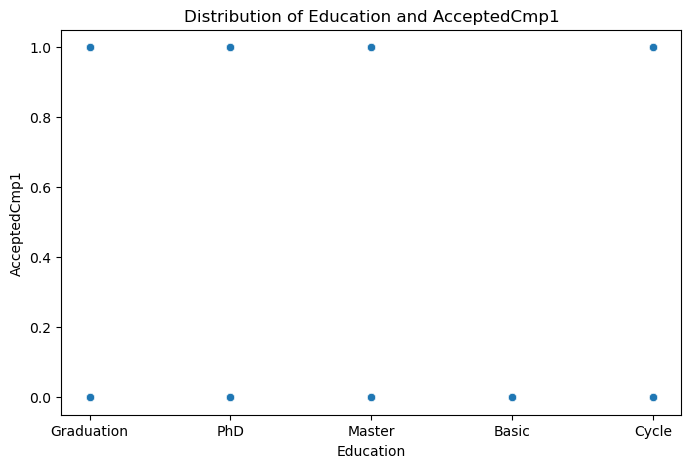

In [9]:
# Birth year and marital status either single or married (except YOLO, alone, & absurd) did not contribute to wine preference. 
# However, high income and non-basic education status showed preference to wines.

# Plot distributions 
plt.figure(figsize=(8, 5))
sns.scatterplot(data=filtered_df, x="Year_Birth", y="AcceptedCmp1")
plt.title('Distribution of Year_Birth and AcceptedCmp1')
plt.xlabel('Year_Birth')
plt.ylabel('AcceptedCmp1')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=filtered_df, x="Income", y="AcceptedCmp1")
plt.title('Distribution of Income and AcceptedCmp1')
plt.xlabel('Income')
plt.ylabel('AcceptedCmp1')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=filtered_df, x="Marital_Status", y="AcceptedCmp1")
plt.title('Distribution of Marital_Status and AcceptedCmp1')
plt.xlabel('Marital_Status')
plt.ylabel('AcceptedCmp1')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=filtered_df, x="Education", y="AcceptedCmp1")
plt.title('Distribution of Education and AcceptedCmp1')
plt.xlabel('Education')
plt.ylabel('AcceptedCmp1')
plt.show()

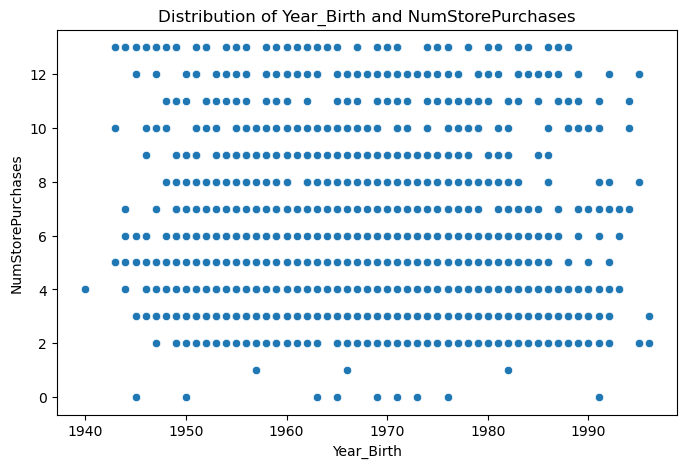

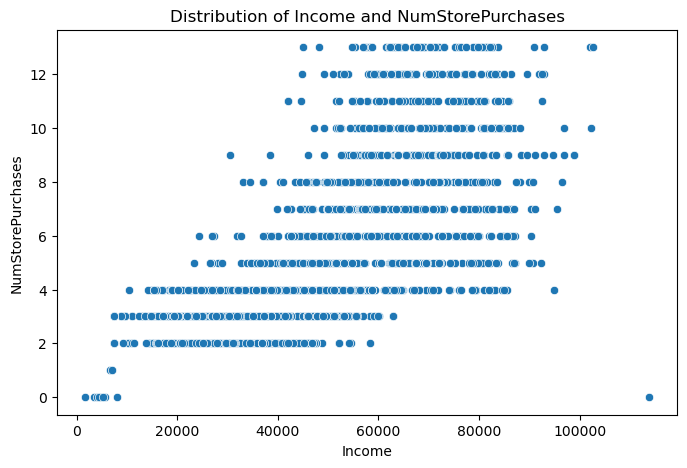

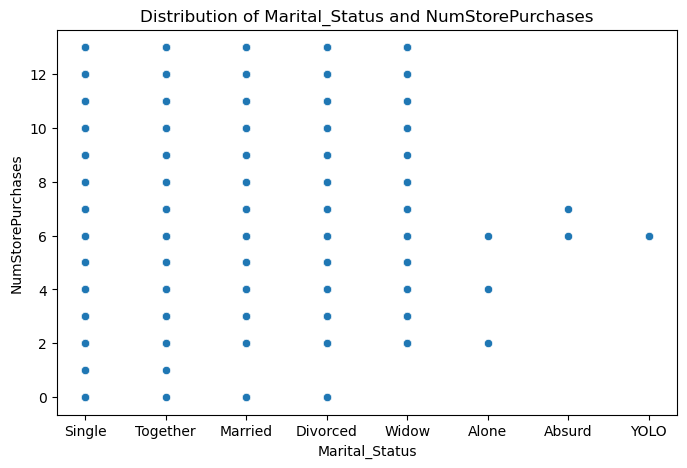

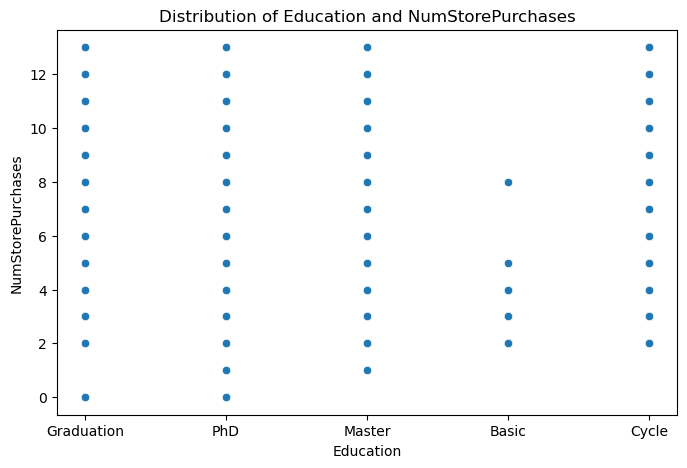

In [10]:
# Higher income tended to accept offer in the first campaign AcceptedCmp1 while Basic education tended NOT to accept 1st offer AcceptedCmp1.

# In the Placement plots, Birth year and marital status either single or married (except YOLO, alone, & absurd) did not contribute to NumStorePurchases. 
# However, high income status showed preference to NumStorePurchases. Basic education showed less purchase (NumStorePurchases)

# Plot distributions 
plt.figure(figsize=(8, 5))
sns.scatterplot(data=filtered_df, x="Year_Birth", y="NumStorePurchases")
plt.title('Distribution of Year_Birth and NumStorePurchases')
plt.xlabel('Year_Birth')
plt.ylabel('NumStorePurchases')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=filtered_df, x="Income", y="NumStorePurchases")
plt.title('Distribution of Income and NumStorePurchases')
plt.xlabel('Income')
plt.ylabel('NumStorePurchases')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=filtered_df, x="Marital_Status", y="NumStorePurchases")
plt.title('Distribution of Marital_Status and NumStorePurchases')
plt.xlabel('Marital_Status')
plt.ylabel('NumStorePurchases')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=filtered_df, x="Education", y="NumStorePurchases")
plt.title('Distribution of Education and NumStorePurchases')
plt.xlabel('Education')
plt.ylabel('NumStorePurchases')
plt.show()

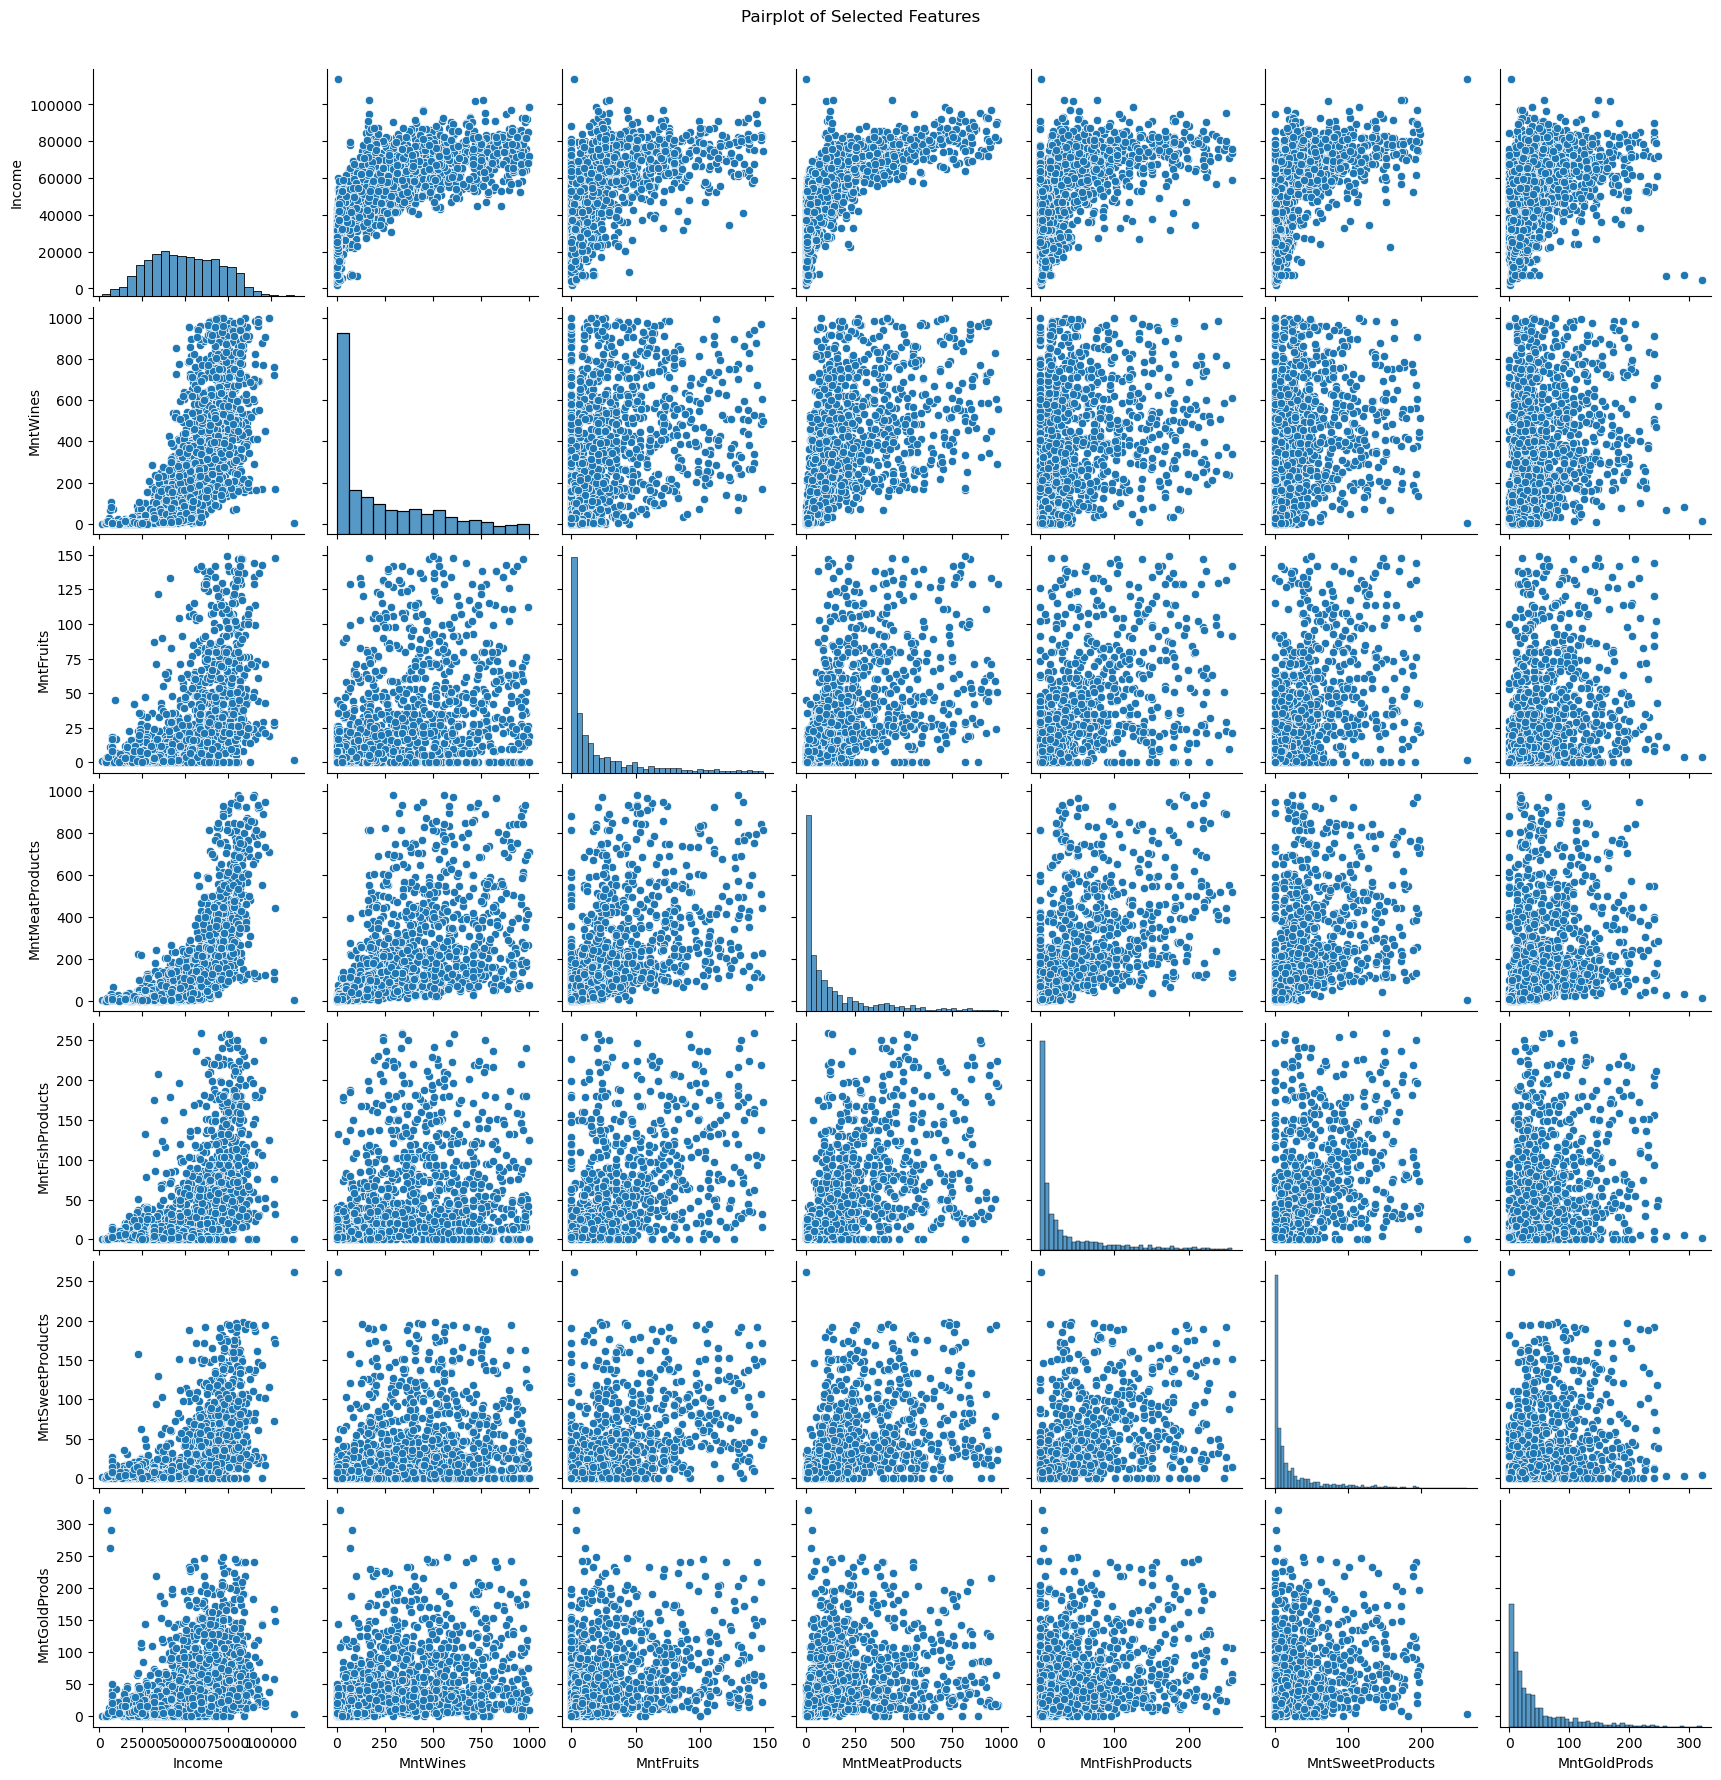

In [14]:
# Feature Selection & Preprocessing

# Select relevant features
features = ['Income', 'MntWines','MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds' ]
X = filtered_df[features]

# Standardize the features
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X))

# Pairplot of selected features
sns.pairplot(filtered_df[features])
plt.suptitle('Pairplot of Selected Features', y=1.02)
plt.show()

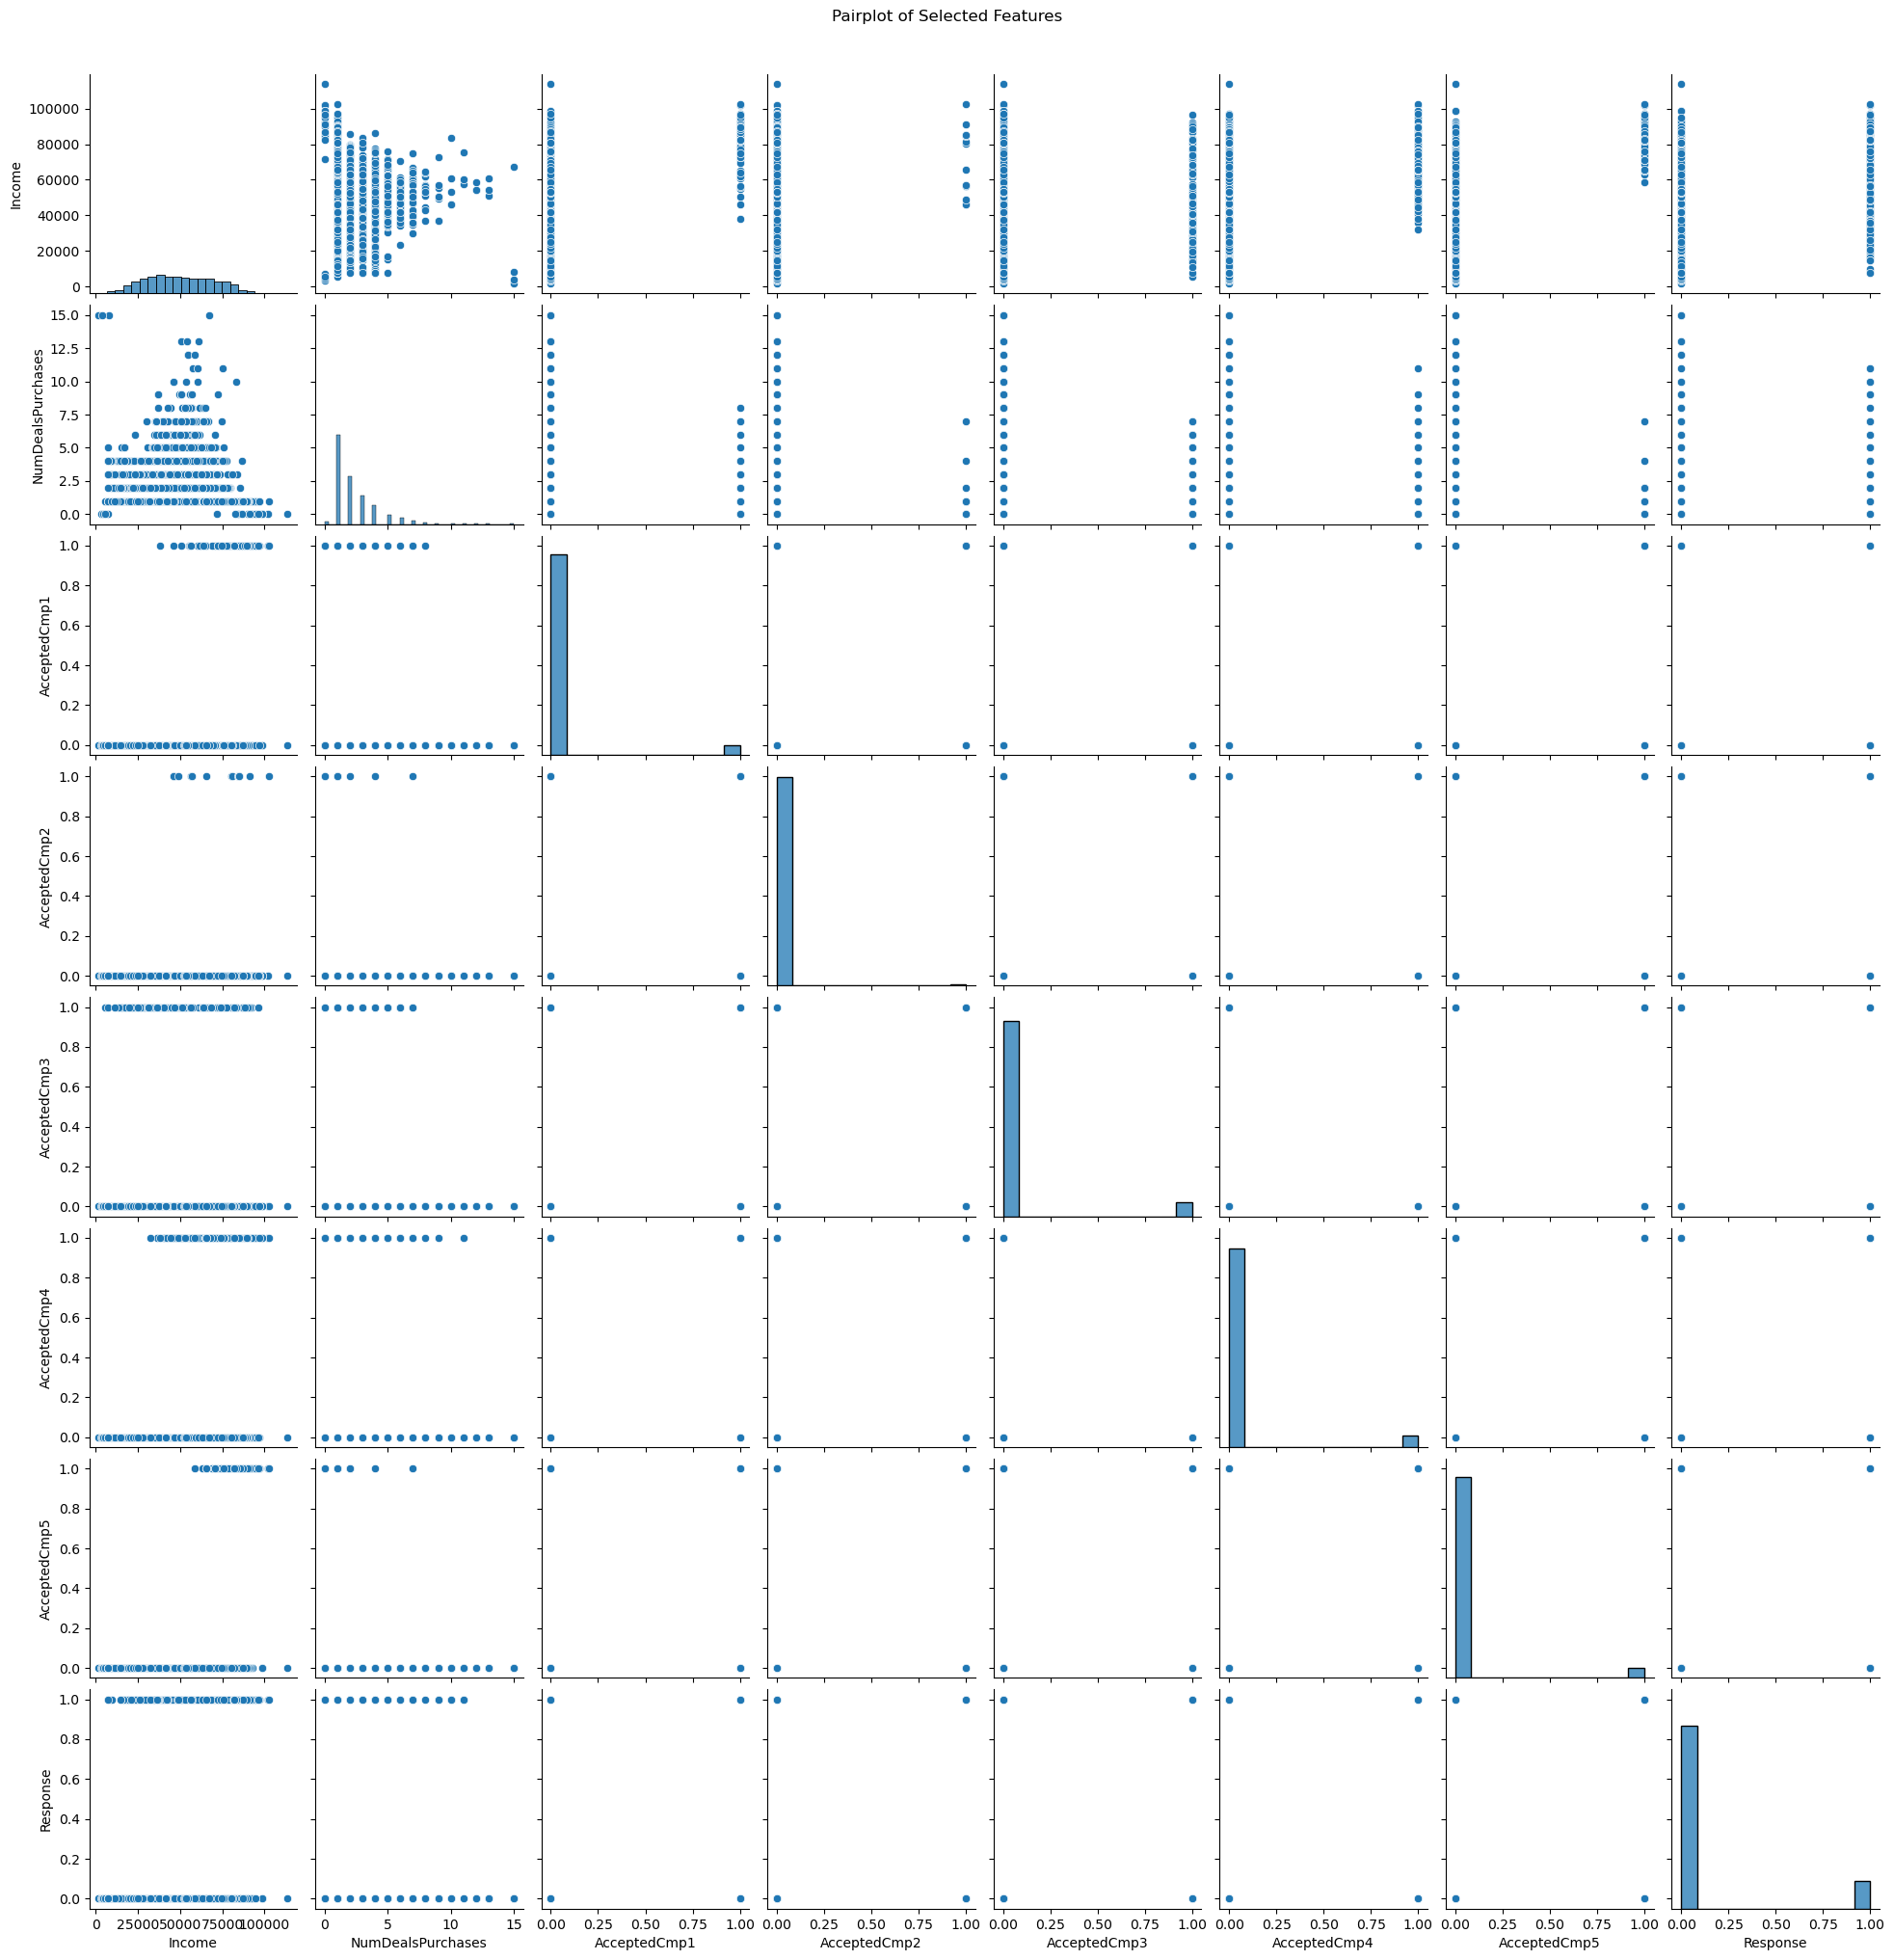

In [15]:
# Select relevant features
features = ['Income','NumDealsPurchases', 'AcceptedCmp1', 'AcceptedCmp2','AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'Response']
X = filtered_df[features]

# Standardize the features
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X))

# Pairplot of selected features
sns.pairplot(filtered_df[features])
plt.suptitle('Pairplot of Selected Features', y=1.02)
plt.show()

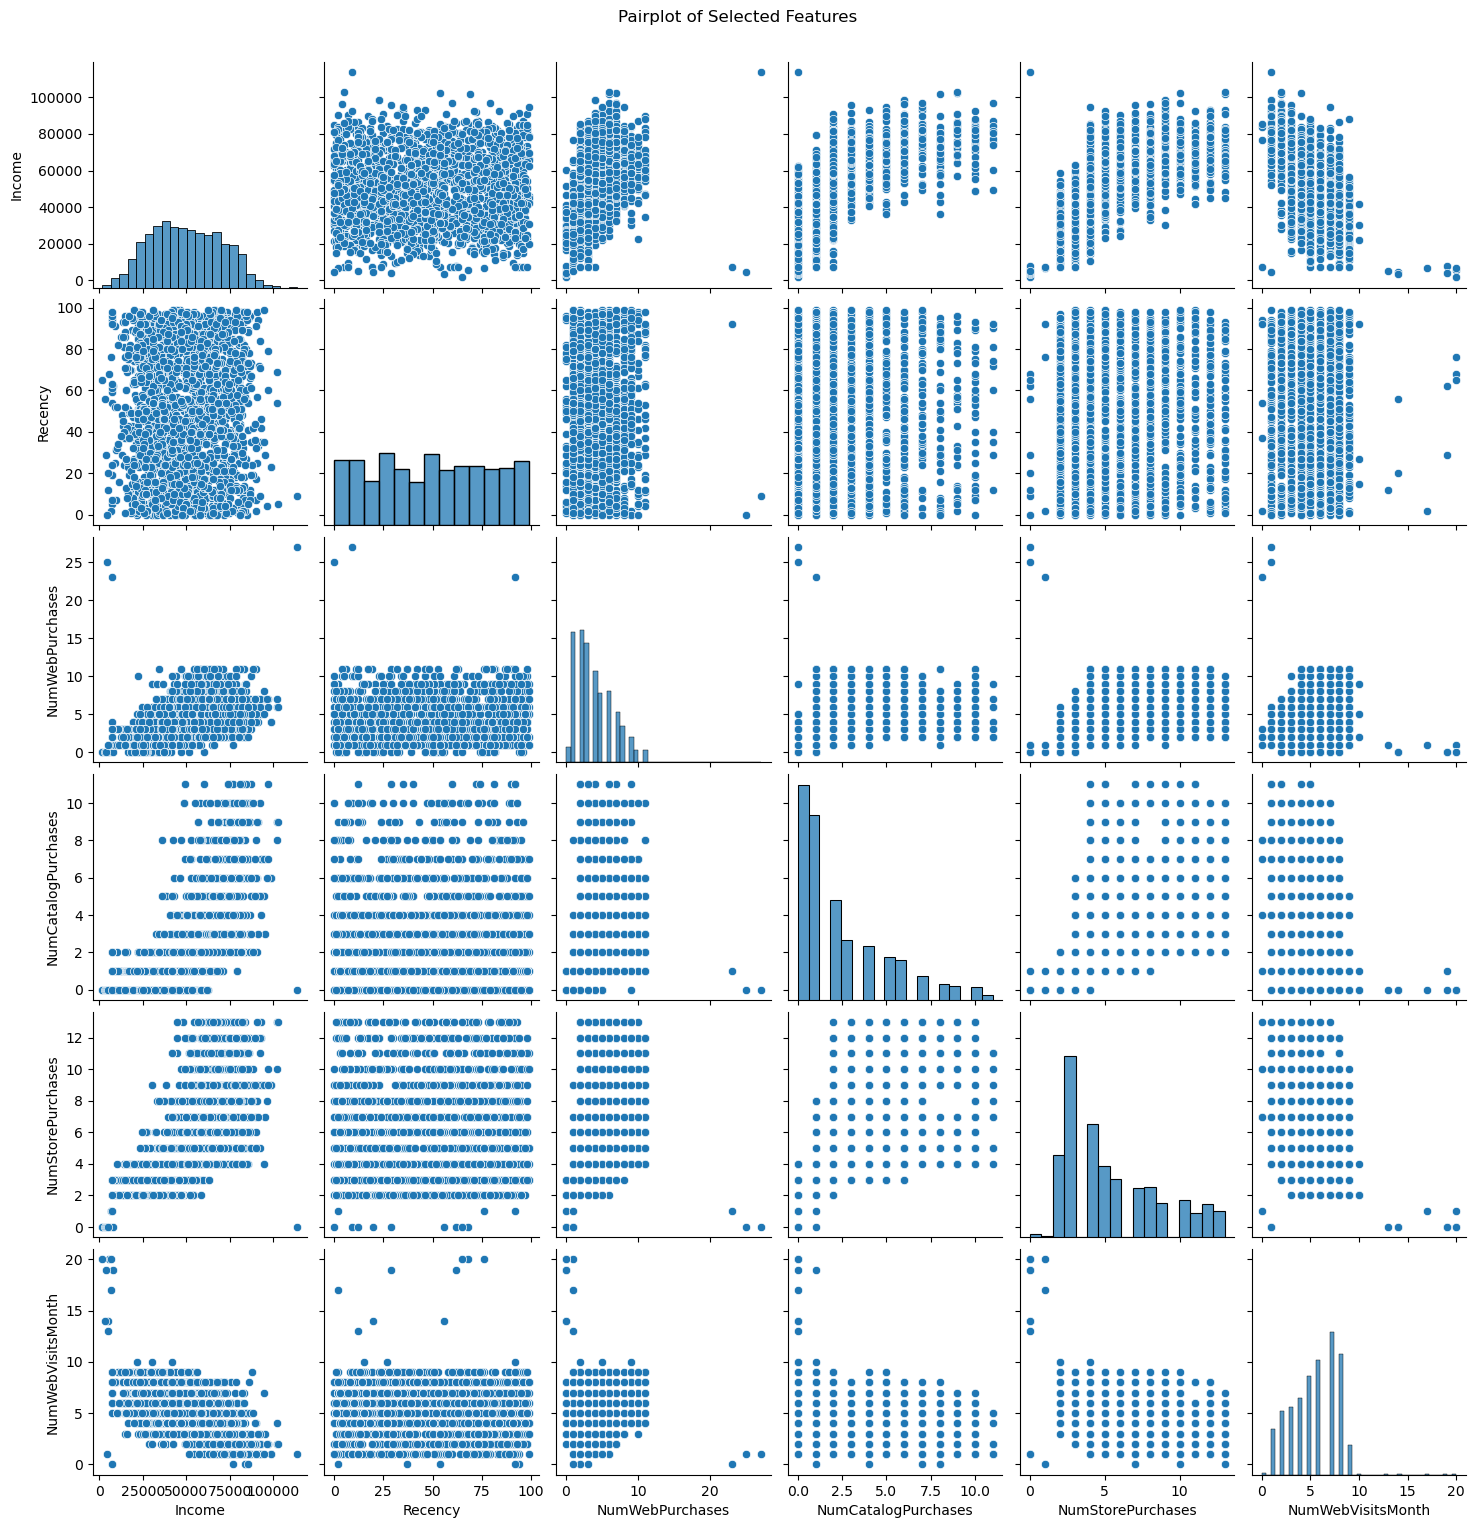

In [16]:
# Select relevant features
features = ['Income', 'Recency','NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases','NumWebVisitsMonth']
X = filtered_df[features]

# Standardize the features
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X))

# Pairplot of selected features
sns.pairplot(filtered_df[features])
plt.suptitle('Pairplot of Selected Features', y=1.02)
plt.show()

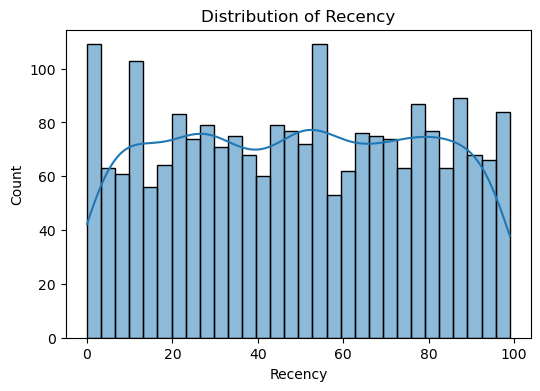

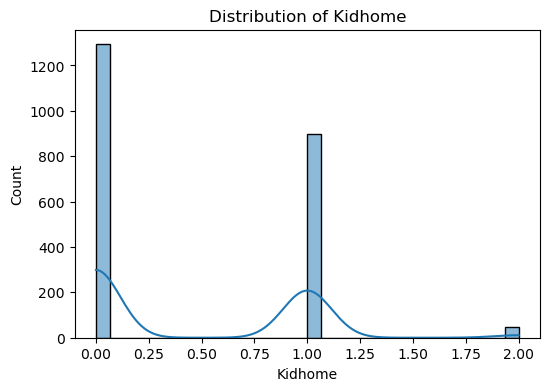

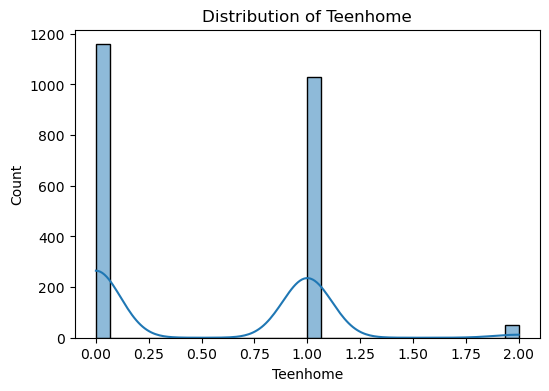

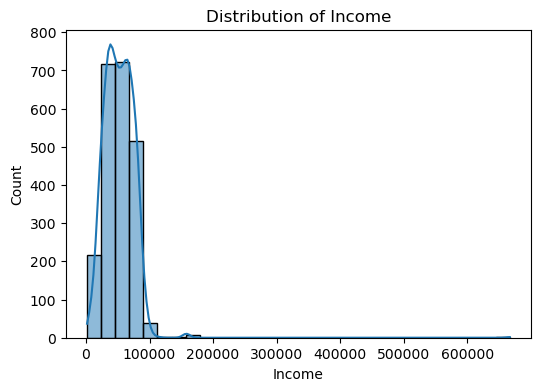

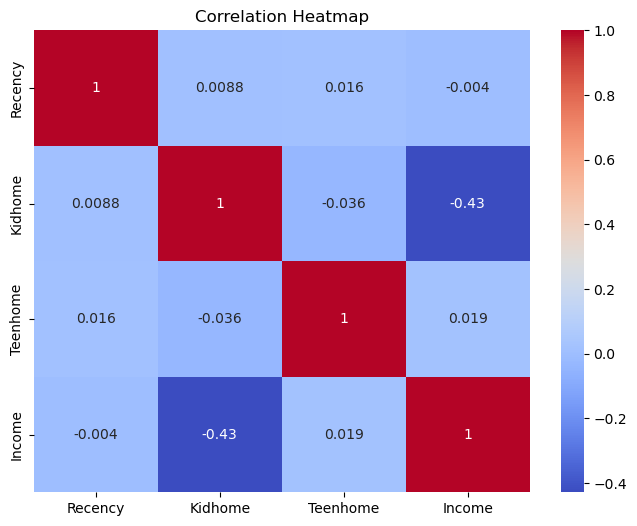

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# Visualize distribution of numeric features
numeric_features = ['Recency', 'Kidhome', 'Teenhome','Income' ]
    
for col in numeric_features:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f'Distribution of {col}')
    plt.show()

# Correlation heatmap
plt.figure(figsize=(8,6))
sns.heatmap(df[numeric_features].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

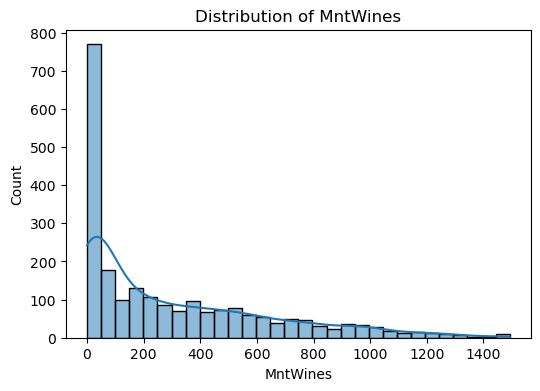

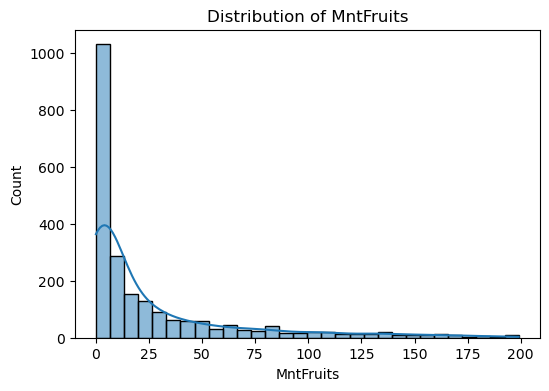

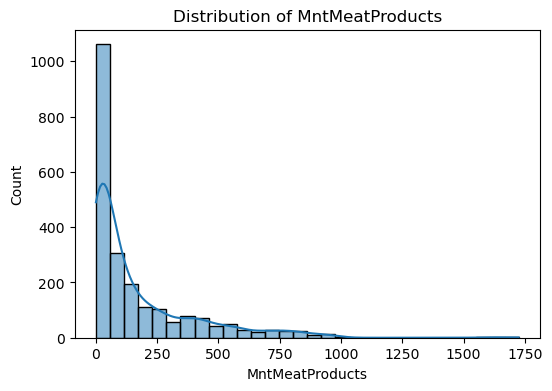

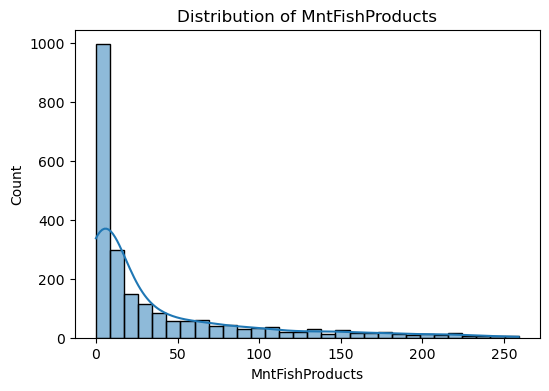

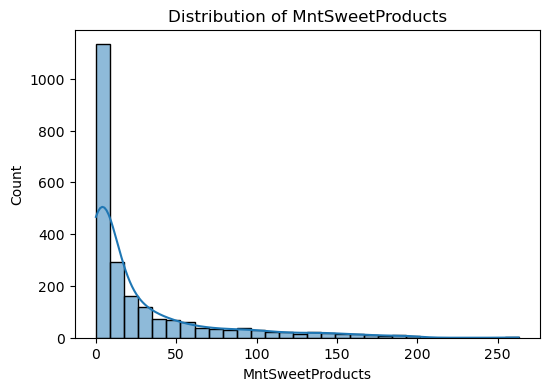

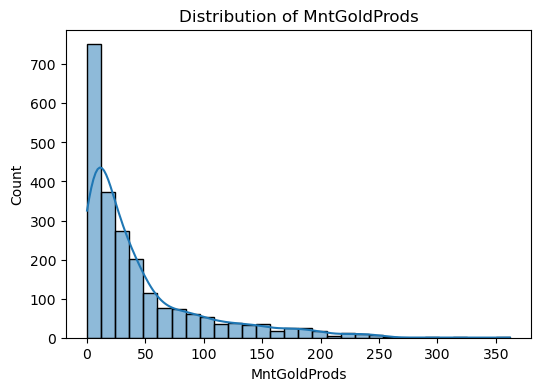

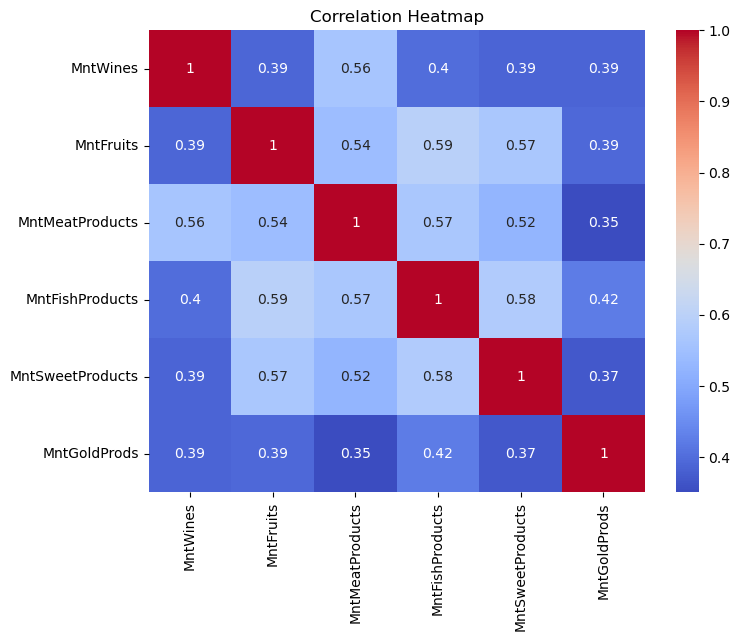

In [18]:
# Correlation heatmap graphical tool displays the strength and direction of relationships between multiple variables in a dataset using color
# +1 (Strong Positive Correlation), 0 (No Correlation), and -1 (Strong Negative Correlation)
# Color Intensity: The brighter or deeper the color, the stronger the relationship. Pale or neutral colors mean weak or zero correlation.
# One color (like blue or red) represents positive correlations. Income and Kidhome had high inverse or negative correlation based on above heatmap.

# Visualize distribution of numeric features
numeric_features = ['MntWines', 'MntFruits','MntMeatProducts','MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
    
for col in numeric_features:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f'Distribution of {col}')
    plt.show()

# Correlation heatmap
plt.figure(figsize=(8,6))
sns.heatmap(df[numeric_features].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

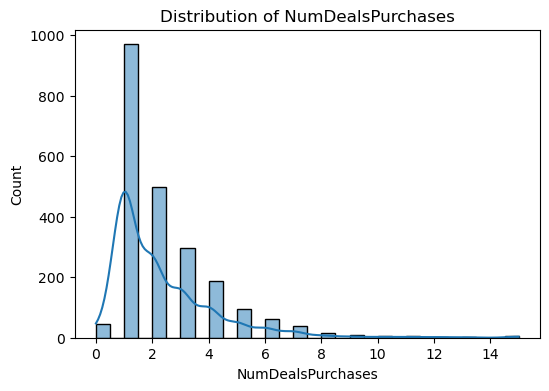

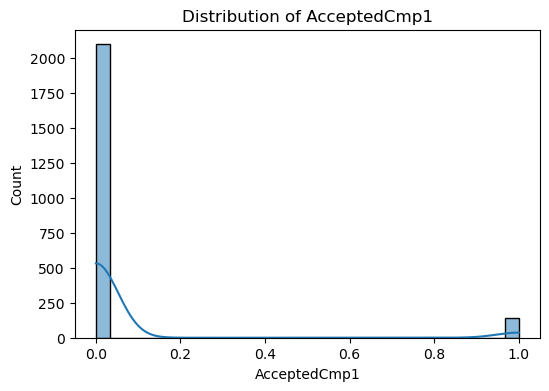

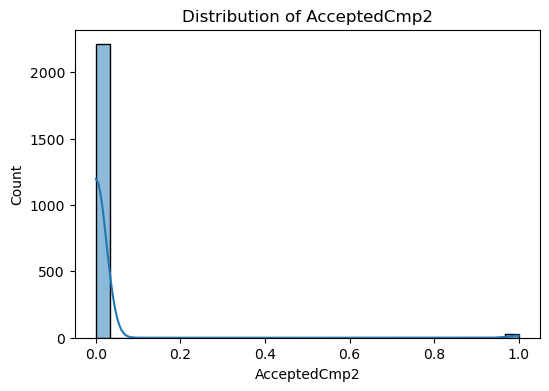

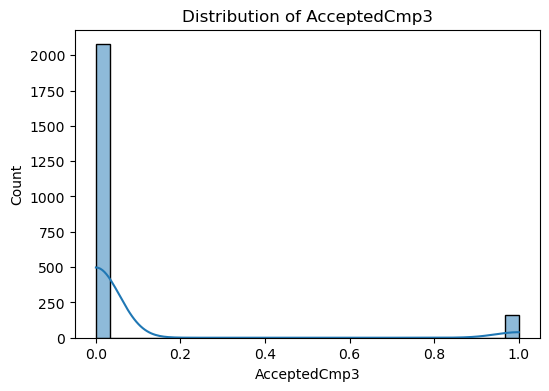

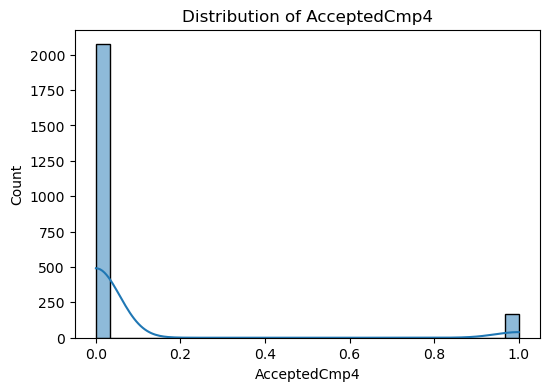

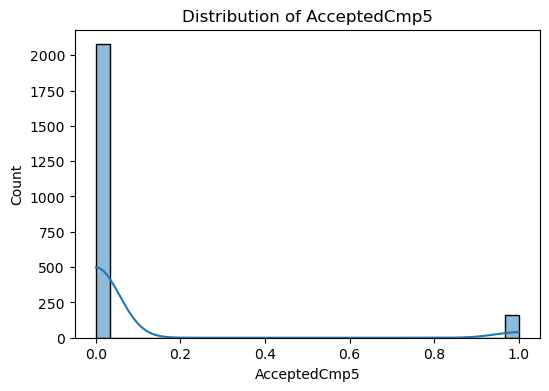

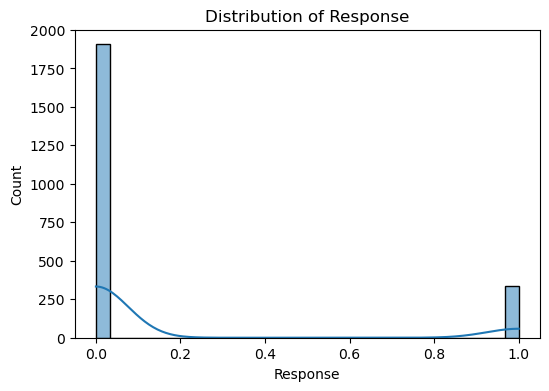

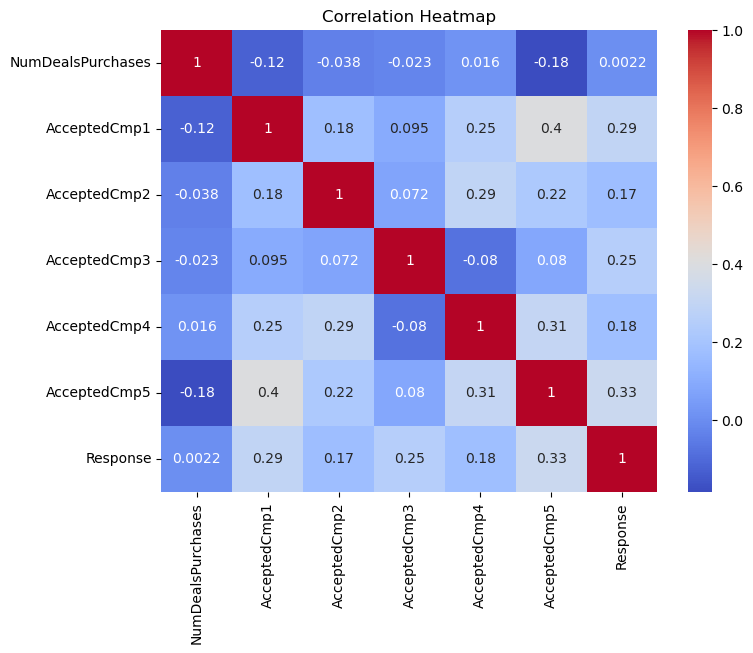

In [19]:
# Product correlation heatmap showed high correlation for MntFruits and MntFishProducts showing healthy food preference at 0.59.
# Followed by MntFruits and MntSweetProducts at 0.57 and MntWines and MntMeatProducts at 0.56. There is high chance that customers who buys meats also buy wines.

# Visualize distribution of numeric features
numeric_features = ['NumDealsPurchases', 'AcceptedCmp1','AcceptedCmp2','AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'Response']
    
for col in numeric_features:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f'Distribution of {col}')
    plt.show()

# Correlation heatmap
plt.figure(figsize=(8,6))
sns.heatmap(df[numeric_features].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [25]:
# On Promotion AcceptedCmp1 (customer accepted the offer in the 1st campaign) and AcceptedCmp5 (customer accepted offer in last campaign) are positively correlated

In [20]:
# NumCatalogPurchases (number of purchases made using a catalogue) and NumStorePurchases number of purchases made directly in stores) are positively correlated at 0.52

# import pandas as pd
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# --- 1. SETUP ORIGINAL DATA ---
X_raw, y_raw = make_classification(n_samples=2240, n_features=28, n_informative=6, random_state=42)
df = pd.DataFrame(X_raw, columns=[f'feature_{i}' for i in range(28)])
df['NumStorePurchases'] = y_raw

# --- 2. CREATE THE FILTERED_DF ---
# (Example filter: keeping only rows where feature_0 is positive)
filtered_df = df[df['feature_0'] > 0].reset_index(drop=True)
print(f"Original shape: {df.shape} | Filtered shape: {filtered_df.shape}\n")

# --- 3. SEPARATE FEATURES AND TARGET ---
# Drop the target column to get features (X), keep only target for (y)
X = filtered_df.drop(columns=['NumStorePurchases'])
y = filtered_df['NumStorePurchases']

# --- 4. TRAIN-TEST SPLIT ---
# Splits data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# --- 5. MODEL TRAINING ---
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# --- 6. EVALUATION ---
predictions = model.predict(X_test)

print(f"Accuracy Score: {accuracy_score(y_test, predictions):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, predictions))


Original shape: (2240, 29) | Filtered shape: (1138, 29)

Accuracy Score: 0.8596

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.81      0.85       116
           1       0.82      0.91      0.86       112

    accuracy                           0.86       228
   macro avg       0.86      0.86      0.86       228
weighted avg       0.86      0.86      0.86       228

